
# Insurance Cost Prediction Using Regularized Regression

## Group 1 — Regression Mini Project

**Algorithms:**
- Ridge Regression (L2)
- Lasso Regression (L1)
- Elastic Net Regression (L1 + L2)

### Project Overview

In this project, we aim to predict individual medical insurance expenses using machine learning regression algorithms.

We use a real-world insurance dataset containing personal and health-related information, including age, sex, BMI, number of children, smoking status, and region.

Our main focus is exploring three regularized regression algorithms: Ridge, Lasso, and Elastic Net.

We also use Linear Regression as a baseline to compare their performance.

### Project Objectives

1. Explore and understand the insurance dataset.
2. Identify relationships between features and insurance expenses.
3. Apply preprocessing techniques to prepare the data.
4. Implement Ridge, Lasso, and Elastic Net regression.
5. Evaluate model performance using MAE, MSE, RMSE, and R².
6. Compare model performance against Linear Regression.
7. Optimize hyperparameters using GridSearchCV.
8. Interpret the results and identify the best-performing model.

### Problem Statement

Medical insurance expenses vary depending on individual characteristics.

The objective is to develop regression models capable of predicting insurance expenses based on the available features.

**Machine Learning Task:** Supervised Learning — Regression

**Target Variable:** `expenses`



## Regression Algorithms

### 1. Ridge Regression (L2 Regularization)

Ridge Regression is an extension of Linear Regression that adds an L2 regularization penalty to the loss function.

**How it works:**

Ridge minimizes prediction errors while penalizing large coefficient values.

The L2 penalty is calculated using the sum of squared coefficients.

**Objective function:**

$$
\min_{\beta_0,\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha\sum_{j=1}^{p}\beta_j^2
\right]
$$

Where:
- $y_i$: Actual value.
- $\hat{y}_i$: Predicted value.
- $\beta_j$: Feature coefficient.
- $\alpha$: Regularization strength.

**Advantages:**
- Helps reduce overfitting.
- Useful when features are highly correlated.
- Reduces the magnitude of coefficients.

**Limitations:**
- Usually does not eliminate features entirely.
- Requires selecting an appropriate alpha value.
- May underfit if regularization is too strong.

**When to use it:**

Ridge is useful when most features are relevant and we want to reduce overfitting without removing them.


### 2. Lasso Regression (L1 Regularization)

Lasso Regression uses L1 regularization, which adds a penalty based on the absolute values of coefficients.

**How it works:**

Lasso reduces coefficient magnitudes and can force some coefficients to become exactly zero.

This allows Lasso to perform automatic feature selection.

**Objective function:**

$$
\min_{\beta_0,\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha\sum_{j=1}^{p}|\beta_j|
\right]
$$

**Advantages:**
- Automatically performs feature selection.
- Can simplify the model.
- Helps reduce overfitting.

**Limitations:**
- May remove useful features when alpha is too high.
- Can be unstable when features are highly correlated.
- Requires appropriate hyperparameter selection.

**When to use it:**

Lasso is useful when a dataset contains potentially unnecessary features and model simplicity is important.


### 3. Elastic Net Regression

Elastic Net combines L1 and L2 regularization.

It combines the feature-selection ability of Lasso with the coefficient-shrinkage behavior of Ridge.

**How it works:**

Elastic Net minimizes prediction errors while applying both absolute-value and squared-coefficient penalties.

**Objective function:**

$$
\min_{\beta_0,\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha\left(
r\sum_{j=1}^{p}|\beta_j|
+
(1-r)\sum_{j=1}^{p}\beta_j^2
\right)
\right]
$$

Where:
- $\alpha$: Overall regularization strength.
- $r$: Balance between L1 and L2 penalties.

In Scikit-learn, the mixing parameter is called `l1_ratio`. Its objective uses normalized loss and penalty factors, so the formula above is a conceptual representation rather than the exact implementation.

**Advantages:**
- Combines the benefits of Ridge and Lasso.
- Can perform feature selection.
- Can handle highly correlated features.

**Limitations:**
- Requires tuning alpha and l1_ratio.
- More complex to configure than Ridge or Lasso.
- Does not always outperform simpler models.

**When to use it:**

Elastic Net is useful when the dataset contains correlated features and feature selection is also desirable.


### Main Difference Between the Algorithms

| Algorithm | Regularization | Feature Selection | Main Purpose |
|---|---|---|---|
| Ridge | L2 | Generally no | Reduce coefficient magnitudes |
| Lasso | L1 | Yes | Remove unnecessary features |
| Elastic Net | L1 + L2 | Yes | Combine both approaches |

**Note:** Regularization helps control model complexity but does not guarantee better predictive performance.


In [2]:
import pandas as pd
import numpy as np
import kagglehub
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


## Dataset Overview

### Dataset Source

The dataset used in this project is the Insurance Premium Prediction dataset, downloaded from Kaggle using `kagglehub`.

**Dataset:** `noordeen/insurance-premium-prediction`

**File:** `insurance.csv`

### Dataset Description

The dataset contains 1,338 records and 7 columns before cleaning.

Each row represents an individual with personal characteristics and associated medical insurance expenses.

### Dataset Features

| Feature | Description | Data Type |
|---|---|---|
| age | Age of the individual | Numerical |
| sex | Sex of the individual | Categorical |
| bmi | Body Mass Index | Numerical |
| children | Number of dependent children | Numerical |
| smoker | Smoking status | Categorical |
| region | Residential region | Categorical |
| expenses | Medical insurance expenses | Numerical |

### Prediction Target

Our target variable is `expenses`.

We aim to predict this value using the remaining six features.

### Initial Data Exploration

We use:
- `head()` and `tail()` to inspect records.
- `info()` to examine data types and non-null counts.
- `describe()` to calculate descriptive statistics.
- `isnull()` to identify missing values.
- `duplicated()` to check duplicate records.


In [3]:
dataset_path = kagglehub.dataset_download(
    "noordeen/insurance-premium-prediction"
)

# Load the CSV file
file_path = Path(dataset_path) / "insurance.csv"

df = pd.read_csv(file_path, low_memory=False)

# Display the first 5 rows
df.head()

Using Colab cache for faster access to the 'insurance-premium-prediction' dataset.


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [4]:
df.tail()

,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000



## Data Cleaning

Data cleaning is an important step before training machine learning models.

### Missing Values

We checked the dataset for missing values using `isnull().sum()`.

**Result:** No missing values were found.

Therefore, no missing-value imputation was required.

### Duplicate Records

We used `duplicated().sum()` to identify duplicate rows.

**Result:** One duplicate record was identified and removed.

After removing duplicates, the dataset contains **1,337 records**.

### Why Data Cleaning Matters

- Prevents unnecessary duplicate information.
- Improves dataset consistency.
- Ensures the models are trained on properly prepared data.

After cleaning, the dataset was ready for exploratory data analysis.


In [7]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
expenses,0


In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   object 
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   expenses  1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 83.6+ KB



## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset, identify patterns, detect outliers, and investigate relationships between features and insurance expenses.

### EDA Objectives

1. Understand the distribution of insurance expenses.
2. Identify potential outliers.
3. Examine correlations between numerical features.
4. Investigate relationships between age, BMI, children, and expenses.
5. Compare insurance expenses across smoking status, sex, and region.

### Visualizations

We use the following visualizations:

- Histograms to explore distributions.
- Boxplots to detect potential outliers.
- Correlation heatmaps to examine numerical relationships.
- Scatter plots to explore relationships between numerical variables and expenses.
- Bar charts to compare average expenses across categories.


In [12]:
df['smoker'].value_counts()

,count
smoker,
no,1063
yes,274


In [13]:
df['sex'].value_counts()

,count
sex,
male,675
female,662


### Insurance Expenses Distribution

The histogram shows a positively skewed distribution of insurance expenses.

Most individuals have relatively low expenses, while a smaller number have significantly higher expenses.

This suggests that insurance costs are not normally distributed and that large expenses may influence model performance.

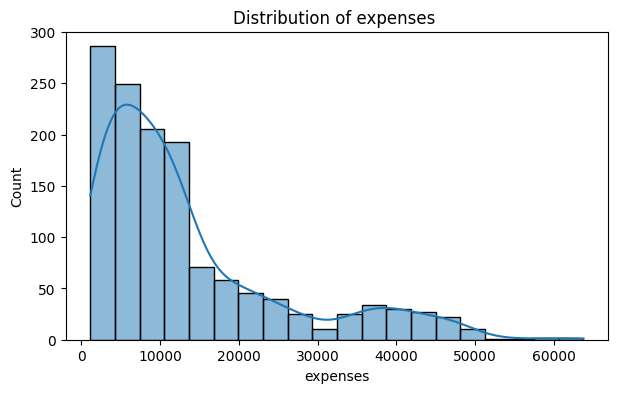

In [14]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="expenses", bins=20, kde=True)

plt.title("Distribution of expenses ")

plt.show()

### Outlier Detection

The boxplot identifies several high-value observations that lie beyond the upper whisker.

We calculate the Interquartile Range (IQR) to determine potential outlier boundaries.

These observations are not automatically removed because high insurance expenses may represent valid real-world cases.


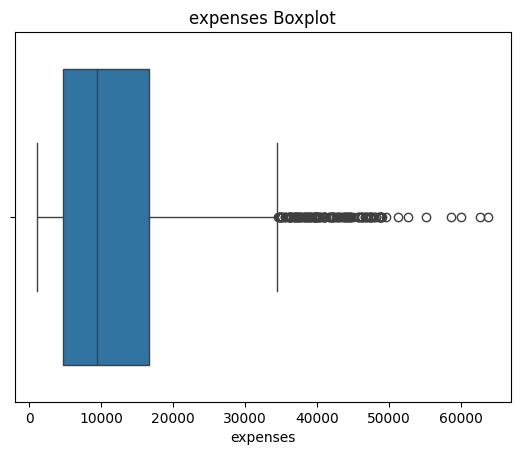

In [15]:
sns.boxplot(x=df['expenses'])
plt.title('expenses Boxplot')
plt.show()

In [38]:
Q1 = df["expenses"].quantile(0.25)
Q3 = df["expenses"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower, upper

,0
age,0
sex,0
bmi,0
children,0
smoker,0


In [39]:
outliers = df[
    (df["expenses"] < lower) |
    (df["expenses"] > upper)
]

print("Number of outliers:", len(outliers))
print(outliers[["expenses"]])

Number of outliers: 139
      expenses
14    39611.76
19    36837.47
23    37701.88
29    38711.00
30    35585.58
...        ...
1300  62592.87
1301  46718.16
1303  37829.72
1313  36397.58
1323  43896.38

[139 rows x 1 columns]


### Correlation Analysis

The correlation heatmap shows the linear relationships between age, BMI, children, and expenses.

Age and BMI show positive relationships with insurance expenses.

The number of children has a weaker linear relationship with the target.

Correlation does not necessarily indicate causation.

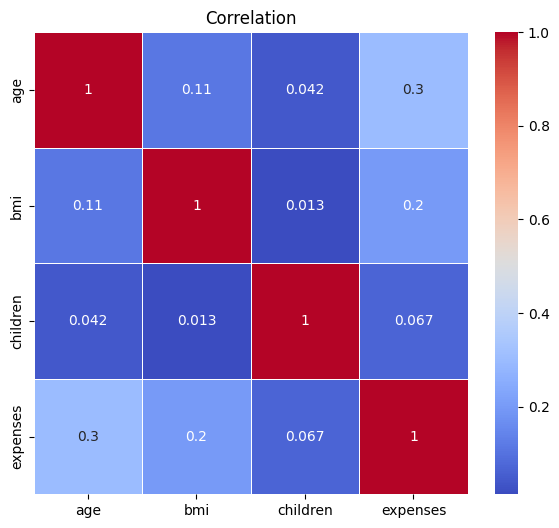

In [17]:
numeric_cols = ["age", "bmi", "children", "expenses"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.5)

plt.title("Correlation")
plt.show()


### Age vs. Expenses

The scatter plot shows that insurance expenses generally increase with age.

Smokers also tend to have higher expenses than non-smokers across different age groups.

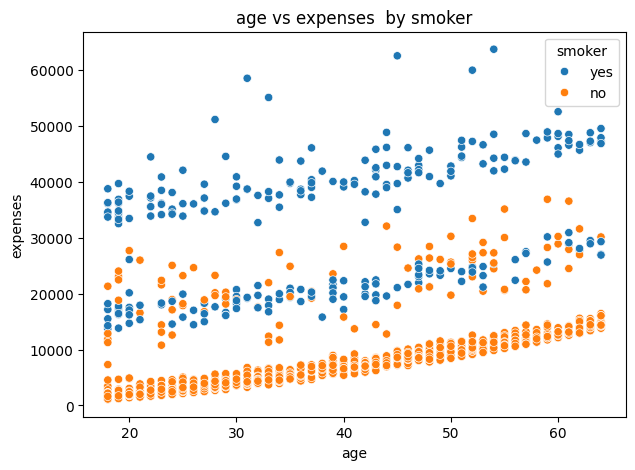

In [18]:
plt.figure(figsize=(7,5))
sns.scatterplot(x="age", y="expenses", hue="smoker", data=df)

plt.title("age vs expenses  by smoker")
plt.xlabel("age")
plt.ylabel("expenses")
plt.show()

### BMI vs. Expenses

BMI shows a relationship with insurance expenses, particularly when smoking status is considered.

Smokers with higher BMI often have higher insurance expenses.

This suggests that the combination of BMI and smoking status may be important for predicting expenses.

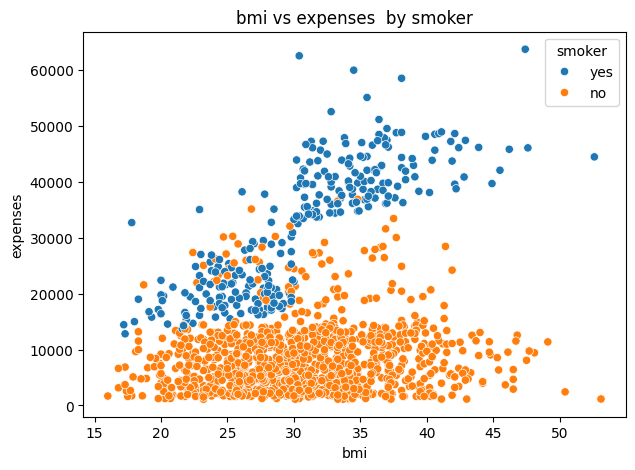

In [19]:
plt.figure(figsize=(7,5))
sns.scatterplot(x="bmi", y="expenses", hue="smoker", data=df)

plt.title("bmi vs expenses  by smoker")
plt.xlabel("bmi")
plt.ylabel("expenses")
plt.show()

### Number of Children vs. Expenses

The number of children does not show a strong or consistent relationship with insurance expenses.

Other features, especially smoking status and age, appear more influential in the visual analysis.

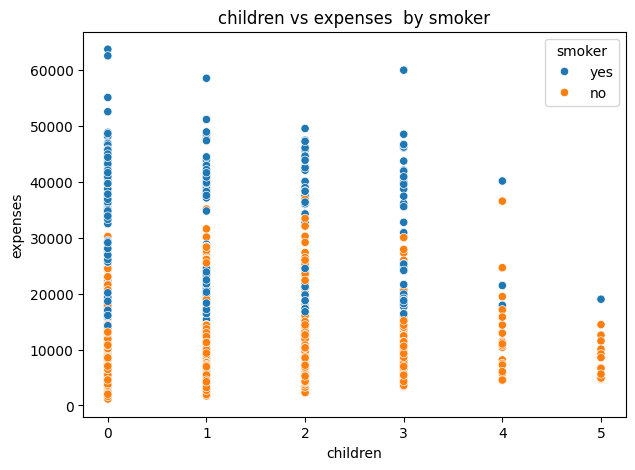

In [20]:
plt.figure(figsize=(7,5))
sns.scatterplot(x="children", y="expenses" , hue="smoker", data=df)

plt.title("children vs expenses  by smoker")
plt.xlabel("children")
plt.ylabel("expenses")
plt.show()

### Average Expenses by Smoking Status

The bar chart shows a large difference in average expenses between smokers and non-smokers.

Smokers have substantially higher average medical insurance expenses.

**Key Insight:** Smoking status is an important predictor of insurance expenses in this dataset.

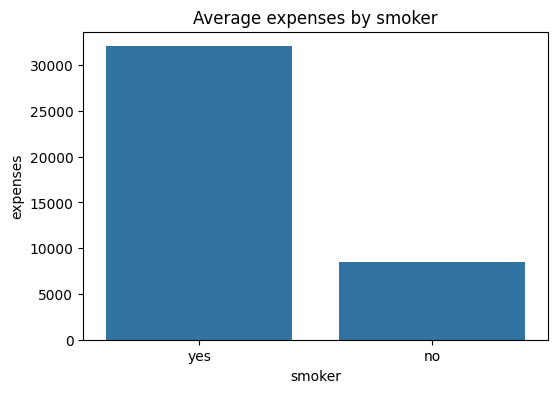

In [21]:
df.groupby("smoker")["expenses"].mean()
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="smoker", y="expenses", estimator=np.mean, errorbar=None)
plt.title("Average expenses by smoker")
plt.xlabel("smoker")
plt.ylabel("expenses")
plt.show()

### Average Expenses by Sex

The chart compares average insurance expenses between male and female individuals.

Any observed difference should be interpreted carefully because other features, including age and smoking status, may affect the overall group averages.

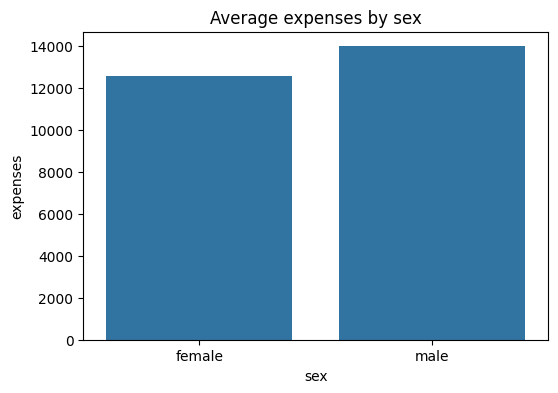

In [22]:
df.groupby("sex")["expenses"].mean()
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="sex", y="expenses", estimator=np.mean, errorbar=None)
plt.title("Average expenses by sex")
plt.xlabel("sex")
plt.ylabel("expenses")
plt.show()

### Average Expenses by Region

Average expenses vary across the four regions.

However, the regional differences appear smaller than the difference between smokers and non-smokers.

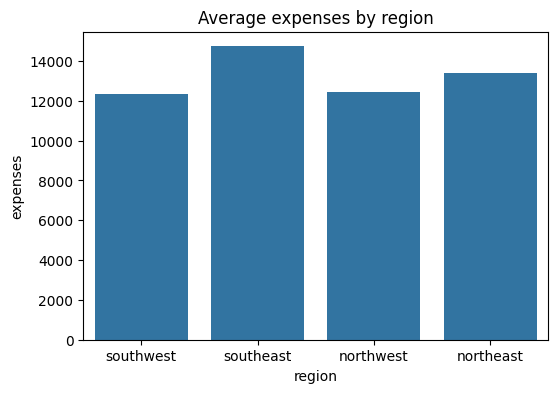

In [23]:
df.groupby("region")["expenses"].mean()
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="region", y="expenses", estimator=np.mean, errorbar=None)
plt.title("Average expenses by region")
plt.xlabel("region")
plt.ylabel("expenses")
plt.show()

### Overall EDA Findings

The exploratory analysis suggests that:
1. Insurance expenses are positively skewed.
2. Several high-expense observations are present.
3. Smoking status is strongly associated with higher expenses.
4. Age and BMI provide useful predictive information.
5. Children, sex, and region show weaker relationships in the visual analysis.

These findings help us understand the features before training our regression models.


## Data Preprocessing

Before training the regression models, we prepare the dataset for machine learning.

### 1. Feature and Target Selection

We separate the dataset into:

**Features (X):**
- age
- sex
- bmi
- children
- smoker
- region

**Target (y):**
- expenses

### 2. Encoding Categorical Variables

Machine learning regression algorithms require numerical input.

Therefore, we apply One-Hot Encoding using `pd.get_dummies()` to convert categorical features into numerical columns.

We use `drop_first=True` to remove one category from each categorical feature, avoiding redundant dummy columns.

We also use `dtype=int` to represent encoded features as integers.

### 3. Train-Test Split

We divide the dataset into:

- **80% Training Data:** Used to train the models.
- **20% Testing Data:** Used to evaluate model performance on unseen data.

We set `random_state=42` to ensure reproducible results.

### 4. Feature Scaling

We use `StandardScaler()` to standardize the features.

Standardization transforms each feature to have approximately zero mean and unit variance on the training dataset.

This is important for regularized regression because features measured on different scales can be penalized unevenly.

We use a Scikit-learn Pipeline to combine scaling and model training.

This ensures scaling parameters are learned from training data rather than the test data.

**Result:** The dataset is prepared for regression model training and evaluation.

In [24]:
X = df[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = df['expenses']

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## Model Implementation

We implement four regression algorithms using Scikit-learn.

### Baseline: Linear Regression

Linear Regression is used as our baseline model.

It predicts insurance expenses using a linear relationship between the input features and target variable.

The baseline allows us to determine whether adding regularization improves predictive performance.

### Ridge Regression

We implement Ridge Regression with:

`alpha = 0.1`

Ridge applies L2 regularization to reduce the magnitude of model coefficients.

### Lasso Regression

We implement Lasso Regression with:

- `alpha = 0.1`
- `max_iter = 10000`

Lasso applies L1 regularization and may set some coefficients to zero.

### Elastic Net Regression

We implement Elastic Net with:

- `alpha = 0.01`
- `l1_ratio = 0.1`
- `max_iter = 10000`

This configuration combines L1 and L2 regularization, with a larger relative contribution from L2.

### Training Process

For each algorithm, we:

1. Create a pipeline containing StandardScaler and the regression model.
2. Fit the pipeline using the training dataset.
3. Predict insurance expenses for the test dataset.
4. Calculate the evaluation metrics.
5. Store the results for comparison.

This approach provides a consistent evaluation process across all four regression algorithms.



## Model Evaluation

To evaluate the performance of our regression models, we use four common regression metrics.

### 1. Mean Absolute Error (MAE)

MAE measures the average absolute difference between actual and predicted values.

- Lower MAE indicates better predictions.
- MAE is expressed in the same units as insurance expenses.

### 2. Mean Squared Error (MSE)

MSE measures the average squared difference between actual and predicted values.

- Penalizes large prediction errors more heavily.
- Lower MSE indicates better performance.

### 3. Root Mean Squared Error (RMSE)

RMSE is the square root of MSE.

- Measures the typical magnitude of prediction errors.
- Uses the same units as the target variable.
- Lower RMSE indicates better predictive performance.

### 4. R² Score

R² measures how much variation in the target variable is explained by the regression model relative to predicting the test-set mean.

- An R² close to 1 indicates a strong fit.
- An R² of 0 means the model performs like predicting the test-set mean.
- R² can be negative when model predictions perform worse than that baseline.

### Initial Model Evaluation Results

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 4177.27 | 5956.63 | 0.8069 |
| Ridge | 4177.53 | 5956.92 | 0.8069 |
| Lasso | 4177.28 | 5956.69 | 0.8069 |
| Elastic Net | 4201.84 | 5984.87 | 0.8051 |

### Results Interpretation

All four models achieved R² scores between approximately 0.805 and 0.807.

This indicates that the models explain approximately 80.5%–80.7% of the variation in the test-set insurance expenses.

**Linear Regression:**
- Achieved the lowest RMSE of 5956.63.
- Performed slightly better than the regularized models.

**Ridge Regression:**
- Achieved an RMSE of 5956.92.
- Performed almost identically to the baseline.

**Lasso Regression:**
- Achieved an RMSE of 5956.69.
- Was the best-performing regularized model before tuning.

**Elastic Net Regression:**
- Achieved an RMSE of 5984.87.
- Performed slightly worse than Ridge and Lasso.

### Key Finding

The regularized regression models achieved similar results to standard Linear Regression.

Under the tested configurations, regularization did not provide a meaningful improvement in test-set predictive accuracy.


In [25]:
# Model Comparison
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=0.1),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Elastic Net": ElasticNet(alpha=0.01,l1_ratio=0.1,max_iter=10000)
}

results = []

for name, model in models.items():

    pipeline = make_pipeline(StandardScaler(), model)

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,4177.2676,3.548147e+07,5956.6326,0.8069
1,Ridge,4177.5254,3.548491e+07,5956.9210,0.8069
2,Lasso,4177.2845,3.548220e+07,5956.6939,0.8069
3,Elastic Net,4201.8397,3.581864e+07,5984.8679,0.8051



## Model Performance Comparison

To compare the regression algorithms, we visualize their performance using RMSE and R² scores.

### RMSE Comparison

RMSE helps us compare prediction errors between different models.

A lower RMSE indicates more accurate predictions under this evaluation metric.

The results show that:
- Linear Regression achieved the lowest RMSE.
- Lasso and Ridge performed very similarly.
- Elastic Net produced slightly higher prediction errors.

### R² Comparison

R² measures how much variation in insurance expenses each model explains.

All four models achieved R² scores of approximately 0.80.

This suggests that they have similar explanatory performance on the test dataset.

### Best Model

Based on the lowest RMSE:

**Best Overall Model:** Linear Regression

- MAE: 4177.27
- RMSE: 5956.63
- R²: 0.8069

**Best Regularized Model:** Lasso Regression

- MAE: 4177.28
- RMSE: 5956.69
- R²: 0.8069

### Interpretation

Although Linear Regression performed slightly better, the differences between Linear Regression, Ridge, and Lasso were very small.

This indicates that applying regularization at the selected strengths did not significantly change predictive performance.

We cannot conclude that one algorithm is universally superior from a single train-test split.


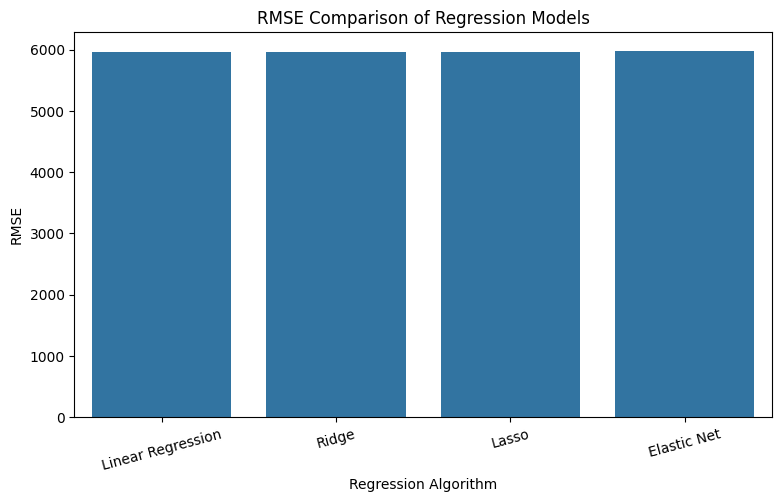

In [26]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Algorithm")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.show()

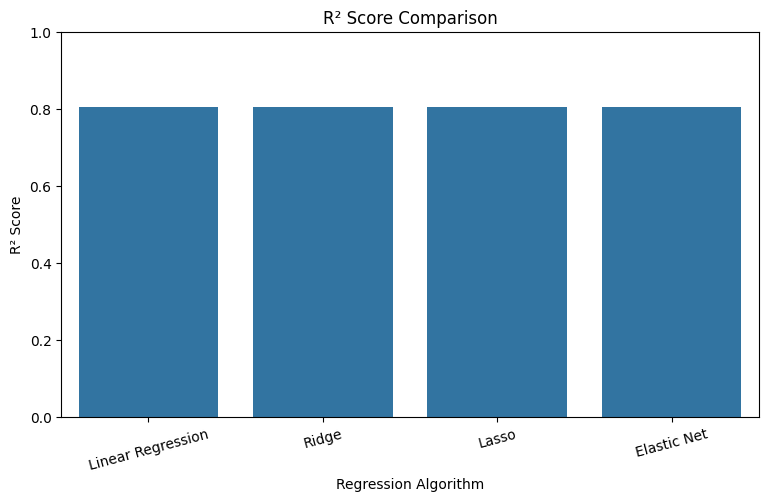

In [27]:
plt.figure(figsize=(9, 5))
sns.barplot( data=results_df, x="Model", y="R2")
plt.title("R² Score Comparison")
plt.xlabel("Regression Algorithm")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [28]:
best_model = results_df.loc[results_df["RMSE"].idxmin()]
print("Best Model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 2))
print("RMSE:", round(best_model["RMSE"], 2))
print("R²:", round(best_model["R2"], 4))

Best Model: Linear Regression
MAE: 4177.27
RMSE: 5956.63
R²: 0.8069



## Hyperparameter Tuning

Hyperparameter tuning is performed to identify suitable regularization settings for Ridge, Lasso, and Elastic Net.

We use `GridSearchCV` with 5-fold cross-validation.

### Objective

Minimize validation RMSE by identifying the best hyperparameter combinations.

### Hyperparameters

**Ridge Regression:**
- alpha: [0.01, 0.1, 1, 10, 100, 1000]

**Lasso Regression:**
- alpha: [0.01, 0.1, 1, 10, 100, 1000]

**Elastic Net Regression:**
- alpha: [0.01, 0.1, 1, 10, 100]
- l1_ratio: [0.1, 0.3, 0.5, 0.7, 0.9]

### Tuning Process

1. Define a parameter grid for each algorithm.
2. Construct a pipeline containing StandardScaler and the regression model.
3. Perform 5-fold cross-validation using GridSearchCV on the training dataset.
4. Select the parameters with the lowest average validation RMSE.
5. Evaluate the selected model using the original test dataset.
6. Compare the results with the original model configurations.

**Important:** The test dataset is not used to select the hyperparameters.

### Best Cross-Validation Results

| Model | Best Alpha | CV RMSE |
|---|---:|---:|
| Ridge | 10 | 6112.90 |
| Lasso | 10 | 6113.21 |
| Elastic Net | 0.01 | 6112.84 |

For Elastic Net, GridSearchCV also selects the best l1_ratio value.

These are cross-validation RMSE values calculated on the training folds, not test-set scores.

### Why Hyperparameter Tuning Matters

The regularization strength controls the balance between fitting the training data and limiting model complexity.

- Small alpha values apply weaker regularization.
- Large alpha values apply stronger regularization.
- Excessive regularization may lead to underfitting.

Cross-validation provides a more systematic way to select parameters than choosing them manually.


In [29]:
from sklearn.model_selection import GridSearchCV

# Define models and parameter grids
tuning_models = {
    "Ridge": (
        Ridge(),
        {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
    ),

    "Lasso": (
        Lasso(max_iter=20000),
        {"lasso__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
    ),

    "Elastic Net": (
        ElasticNet(max_iter=20000),
        {
            "elasticnet__alpha": [0.01, 0.1, 1, 10, 100],
            "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
        }
    )
}

tuned_models = {}
tuning_results = []

for name, (model, params) in tuning_models.items():

    pipeline = make_pipeline(
        StandardScaler(),
        model
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    tuned_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "CV RMSE": -grid.best_score_
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

,Model,Best Parameters,CV RMSE
0,Ridge,{'ridge__alpha': 10},6112.897149
1,Lasso,{'lasso__alpha': 10},6113.206612
2,Elastic Net,"{'elasticnet__alpha': 0.01, 'elasticnet__l1_ra...",6112.839326


In [30]:
tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    tuned_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.round(4))

,Model,MAE,MSE,RMSE,R2
0,Ridge,4202.7979,3.583218e+07,5985.9988,0.8050
1,Lasso,4178.9534,3.555628e+07,5962.9084,0.8065
2,Elastic Net,4201.8397,3.581864e+07,5984.8679,0.8051


,Model,Before Tuning,After Tuning
0,Ridge,5956.92,5986.00
1,Lasso,5956.69,5962.91
2,Elastic Net,5984.87,5984.87


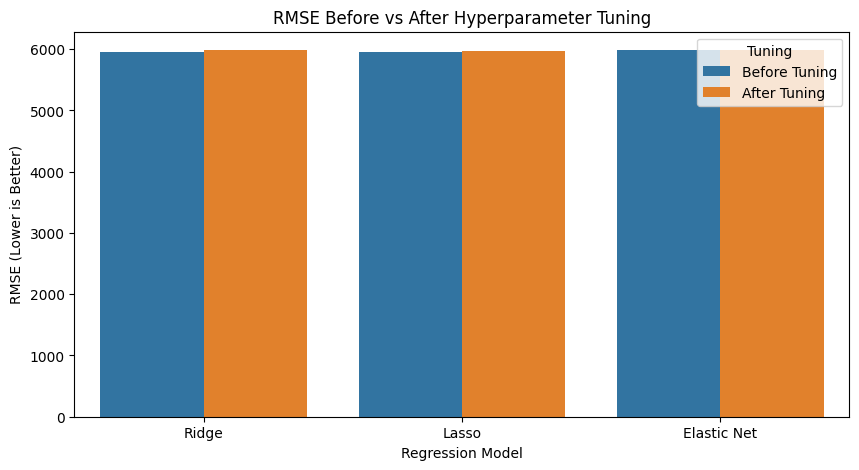

In [31]:
# Compare original results with tuned results
before = results_df[
    results_df["Model"] != "Linear Regression"
][["Model", "RMSE"]].rename(
    columns={"RMSE": "Before Tuning"}
)

after = tuned_results_df[
    ["Model", "RMSE"]
].rename(
    columns={"RMSE": "After Tuning"}
)

comparison = before.merge(after, on="Model")

display(comparison.round(2))

# Visualize results
comparison_plot = comparison.melt(
    id_vars="Model",
    var_name="Tuning",
    value_name="RMSE"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="RMSE",
    hue="Tuning"
)

plt.title("RMSE Before vs After Hyperparameter Tuning")
plt.ylabel("RMSE (Lower is Better)")
plt.xlabel("Regression Model")
plt.show()


## Hyperparameter Tuning Results

After identifying the best hyperparameters using GridSearchCV, we evaluated the tuned models on the test dataset.

### RMSE Comparison

| Model | Before Tuning | After Tuning |
|---|---:|---:|
| Ridge | 5956.92 | 5986.00 |
| Lasso | 5956.69 | 5962.91 |
| Elastic Net | 5984.87 | 5984.87 |

### Interpretation

**Ridge Regression:**
- Test RMSE increased from 5956.92 to 5986.00.
- The tuned model performed slightly worse on the test set.

**Lasso Regression:**
- Test RMSE increased from 5956.69 to 5962.91.
- The original configuration achieved better test performance.

**Elastic Net Regression:**
- Test RMSE remained approximately 5984.87.
- Hyperparameter tuning did not change its test performance.

### Key Finding

Hyperparameter tuning did not improve test RMSE in this experiment.

This does not indicate a failure of GridSearchCV.

GridSearchCV selects parameters based on cross-validation performance rather than the test set.

A configuration that performs better during cross-validation does not necessarily achieve better results on every unseen dataset.

### Conclusion

The original Lasso configuration achieved the lowest test RMSE among our regularized models.

The experiment demonstrates that hyperparameter tuning is useful for systematic parameter selection, but it does not guarantee improved test-set performance.



## Final Conclusion

### Project Summary

In this mini project, we explored three regularized regression algorithms: Ridge, Lasso, and Elastic Net.

Our objective was to predict individual medical insurance expenses using personal and health-related features.

We performed exploratory data analysis, cleaned the dataset, encoded categorical variables, trained regression models, and evaluated their predictive performance.

We also implemented Linear Regression as a baseline and applied hyperparameter tuning using GridSearchCV.

### Key Findings

**1. Exploratory Data Analysis**

- Insurance expenses are positively skewed.
- Smoking status is strongly associated with higher insurance expenses.
- Age and BMI provide useful predictive information.
- The dataset contained one duplicate record, which was removed.

**2. Model Performance**

- All models explained approximately 80% of the variation in insurance expenses.
- Linear Regression achieved the lowest overall RMSE of 5956.63.
- Lasso achieved the lowest RMSE among the regularized models at 5956.69.
- Ridge performed almost identically to Lasso.
- Elastic Net achieved a slightly higher RMSE.

**3. Hyperparameter Tuning**

We used GridSearchCV with 5-fold cross-validation to optimize the model hyperparameters.

Tuning did not improve test-set RMSE for Ridge or Lasso, while Elastic Net's test RMSE remained unchanged.

This shows that hyperparameter tuning does not always improve performance on unseen test data.

### Main Learning Outcomes

Through this project, we learned:

1. How Ridge applies L2 regularization.
2. How Lasso applies L1 regularization and can perform feature selection.
3. How Elastic Net combines L1 and L2 regularization.
4. How to evaluate regression algorithms using multiple metrics.
5. How to compare models and tune hyperparameters using cross-validation.

### Project Limitations

- The dataset contains a relatively small number of records.
- The models use primarily linear relationships between the encoded features and insurance expenses.
- Model performance was evaluated using a single held-out test split.
- Regularization cannot automatically capture nonlinear relationships or complex feature interactions.

### Future Improvements

Possible improvements include:

- Engineering additional features and interaction terms.
- Testing nonlinear regression algorithms.
- Using repeated cross-validation to assess model stability.
- Exploring alternative target transformations.
- Analyzing feature coefficients to understand the impact of regularization.

### Final Takeaway

**Linear Regression achieved the best overall test performance, while Lasso was the best-performing regularized model under the original settings.**

Although regularization did not significantly improve prediction accuracy in this experiment, Ridge, Lasso, and Elastic Net remain valuable techniques for controlling model complexity and reducing overfitting.

The project demonstrates how different regression techniques can be implemented, evaluated, and compared to solve a real-world prediction problem.
